# Proyek Klasifikasi Gambar: Garbage Classification 
- **Nama:** Antonius Vincent Jung
- **Email:** cacc012d6y2282@student.devacademy.id
- **ID Dicoding:** CACC012D6Y2282

## Import Semua Packages/Library yang Digunakan

In [1]:
# Library yang sering digunakan
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
from collections import Counter
from tqdm.notebook import tqdm as tq

# Library Visualisasi
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.patches as mpatches
import seaborn as sns

# Libraries untuk pemrosesan data gambar
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

# Libraries untuk pembangunan model
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras import Model, layers, regularizers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import InputLayer, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import EfficientNetB1
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau,CSVLogger

# import warnings
# warnings.simplefilter(action='ignore', category=FutureWarning)

# Mencetak versi TensorFlow yang sedang digunakan
print(tf.__version__)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


2026-04-06 16:02:45.221794: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775491365.380818      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775491365.432977      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775491365.838360      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775491365.838385      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775491365.838388      55 computation_placer.cc:177] computation placer alr

2.19.0


## Data Preparation

### Data Loading

In [2]:
# Konfigurasi Path 
import os
from pathlib import Path

# Deteksi environment otomatis
IS_KAGGLE = os.path.exists('/kaggle/working')

if IS_KAGGLE:
    BASE_DIR    = Path("/kaggle/input/datasets/sumn2u/garbage-classification-v2/original")
    WORK_DIR    = Path("/kaggle/working")
else:
    BASE_DIR    = Path("original")
    WORK_DIR    = Path(".")

# Path output — semua hasil tulis ke sini
# Format submission
TFJS_DIR        = WORK_DIR / "tfjs_model"
TFLITE_DIR      = WORK_DIR / "tflite"
SAVED_MODEL_DIR = WORK_DIR / "saved_model"

# File spesifik
TFLITE_PATH = TFLITE_DIR / "model.tflite"
LABEL_PATH  = TFLITE_DIR / "label.txt"

# Optional (training support)
AUG_DIR        = WORK_DIR / "augmented/train"
CHECKPOINT_DIR = WORK_DIR / "checkpoints"
LOG_DIR        = WORK_DIR / "logs"

# Buat semua folder
dirs_to_create = [
    TFJS_DIR,
    TFLITE_DIR,
    SAVED_MODEL_DIR,
    AUG_DIR,
    CHECKPOINT_DIR,
    LOG_DIR
]

for d in dirs_to_create:
    d.mkdir(parents=True, exist_ok=True)

print(f"Environment  : {'Kaggle' if IS_KAGGLE else 'Lokal/Colab'}")
print(f"Dataset path : {BASE_DIR}")
print(f"Output path  : {WORK_DIR}")
print(f"GPU          : {tf.config.list_physical_devices('GPU')}")

Environment  : Kaggle
Dataset path : /kaggle/input/datasets/sumn2u/garbage-classification-v2/original
Output path  : /kaggle/working
GPU          : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
CLASS_NAMES = sorted([d.name for d in BASE_DIR.iterdir() if d.is_dir()])
NUM_CLASSES = len(CLASS_NAMES)

print(f"Lokasi Dataset   : {BASE_DIR.resolve()}")
print(f"Jumlah kelas     : {NUM_CLASSES}")
print(f"Nama kelas       : {CLASS_NAMES}")

Lokasi Dataset   : /kaggle/input/datasets/sumn2u/garbage-classification-v2/original
Jumlah kelas     : 10
Nama kelas       : ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


In [4]:
# Mengumpulkan semua path gambar & label
VALID_EXT = ('.jpg','.jpeg')

file_paths = []
labels     = []

for cls in CLASS_NAMES:
    cls_dir = BASE_DIR / cls
    for img_path in cls_dir.iterdir():
        if img_path.suffix.lower() in VALID_EXT:
            file_paths.append(str(img_path))
            labels.append(cls)

print(f"Total gambar terkumpul : {len(file_paths):,}")

Total gambar terkumpul : 12,259


/tmp/ipykernel_55/1236552485.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


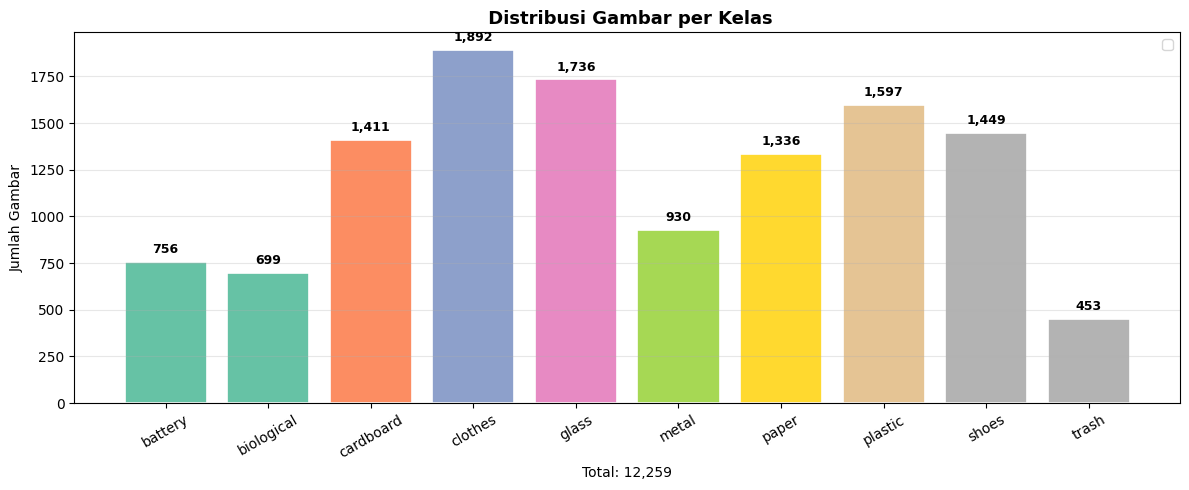

In [5]:
# Distribusi Jumlah Gambar per Kelas (Bar Chart)
count_per_class = Counter(labels)
counts          = [count_per_class[c] for c in CLASS_NAMES]

fig, ax = plt.subplots(figsize=(12, 5))

colors = plt.cm.Set2(np.linspace(0, 1, NUM_CLASSES))
bars   = ax.bar(CLASS_NAMES, counts, color=colors, edgecolor='white', linewidth=1.2)

# Tambahkan nilai di atas tiap bar
for bar, val in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30,
        f'{val:,}', ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

ax.set_title(' Distribusi Gambar per Kelas', fontsize=13, fontweight='bold')
ax.set_xlabel('Kelas')
ax.set_ylabel('Jumlah Gambar')
ax.tick_params(axis='x', rotation=30)
ax.legend()
ax.grid(axis='y', alpha=0.3)

ax.set_xlabel(f'Total: {len(file_paths):,}', fontsize=10)

plt.tight_layout()
plt.show()

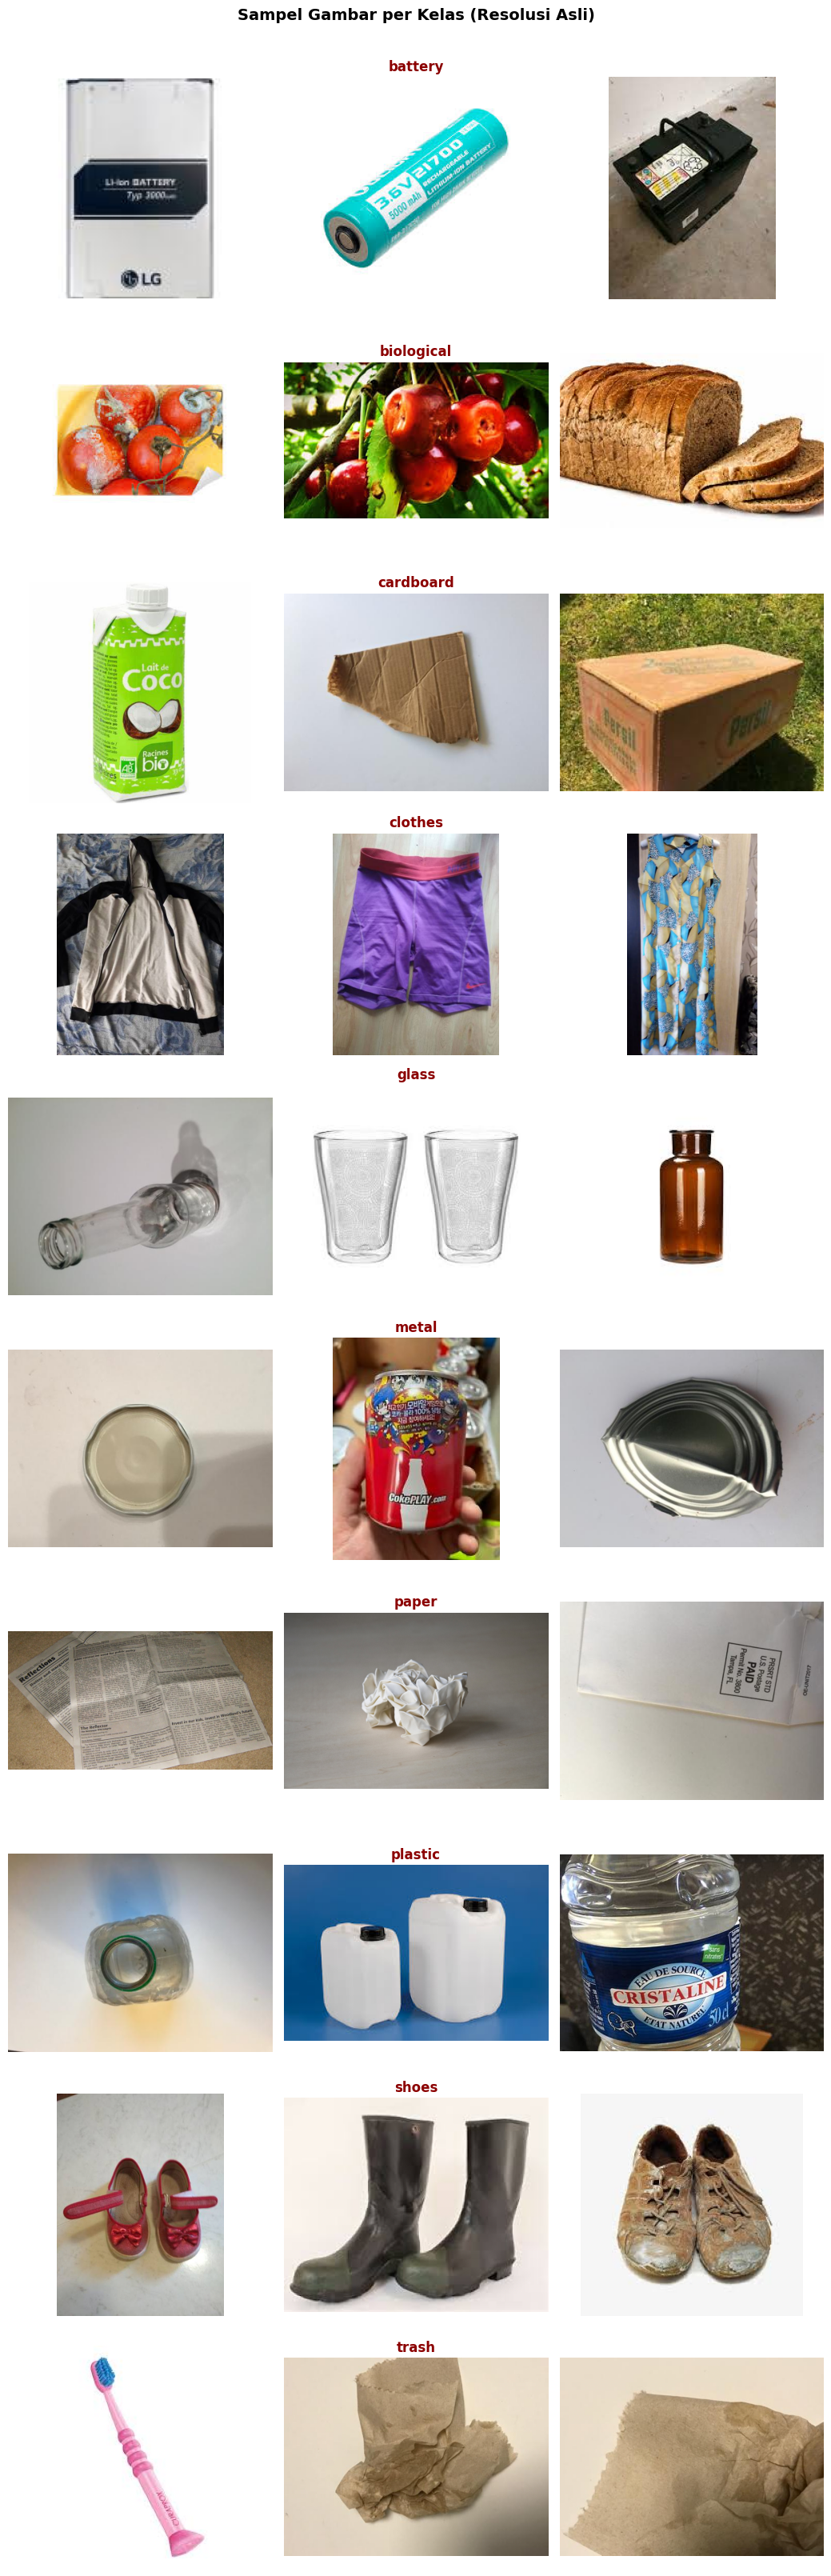

In [6]:
# Sampel Gambar per Kelas (Grid Plot)
SAMPLES_PER_CLASS = 3
cols = SAMPLES_PER_CLASS
rows = NUM_CLASSES

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.2))
fig.suptitle('Sampel Gambar per Kelas (Resolusi Asli)',
             fontsize=14, fontweight='bold', y=1.005)

for row, cls in enumerate(CLASS_NAMES):
    cls_imgs = [p for p, l in zip(file_paths, labels) if l == cls]
    sampled  = sample(cls_imgs, SAMPLES_PER_CLASS)

    for col, img_path in enumerate(sampled):
        img = mpimg.imread(img_path)
        axes[row, col].imshow(img)
        axes[row, col].axis('off')
        if col == 1:
            axes[row, col].set_title(f"{cls}", loc='center', fontweight='bold', color='darkred')


plt.tight_layout()
plt.show()

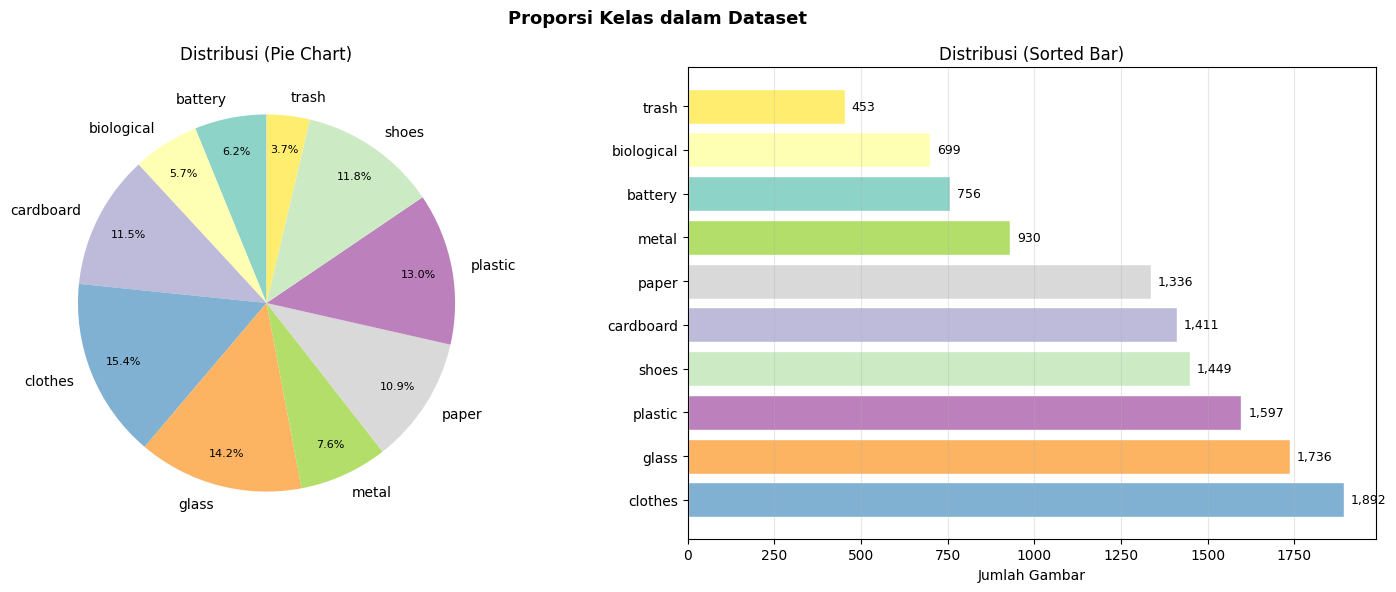

In [7]:
# Pie Chart Proporsi Kelas
counts = [count_per_class[c] for c in CLASS_NAMES]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Proporsi Kelas dalam Dataset', fontsize=13, fontweight='bold')

# Pie chart
colors_pie = plt.cm.Set3(np.linspace(0, 1, NUM_CLASSES))
wedges, texts, autotexts = axes[0].pie(
    counts,
    labels      = CLASS_NAMES,
    autopct     = '%1.1f%%',
    colors      = colors_pie,
    startangle  = 90,
    pctdistance = 0.82
)
for at in autotexts:
    at.set_fontsize(8)
axes[0].set_title('Distribusi (Pie Chart)')

# Horizontal Bar
sorted_idx  = np.argsort(counts)[::-1]
sorted_cls  = [CLASS_NAMES[i] for i in sorted_idx]
sorted_cnt  = [counts[i]      for i in sorted_idx]
sorted_col  = [colors_pie[i]  for i in sorted_idx]

bars = axes[1].barh(sorted_cls, sorted_cnt, color=sorted_col, edgecolor='white')
for bar, val in zip(bars, sorted_cnt):
    axes[1].text(bar.get_width() + 20, bar.get_y() + bar.get_height() / 2,
                 f'{val:,}', va='center', fontsize=9)
axes[1].set_title('Distribusi (Sorted Bar)')
axes[1].set_xlabel('Jumlah Gambar')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

### Data Preprocessing

#### Split Dataset

In [8]:
# TAHAP 1: Train (80%) vs Temp (20%)
X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths,
    labels,
    test_size    = 0.20,
    random_state = 42,
    stratify     = labels   # ← proporsi kelas tetap seimbang
)

# TAHAP 2: Val (10%) vs Test (10%) dari Temp
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size    = 0.50,    # 50% dari 20% = 10% dari total
    random_state = 42,
    stratify     = y_temp
)

total = len(file_paths)
print("Hasil Split ")
print("═" * 44)
print(f"  {'Set':<12} {'Jumlah':>8}   {'Persen':>8}")
print("─" * 44)
print(f"  {'Train':<12} {len(X_train):>8,}   {len(X_train)/total*100:>7.1f}%")
print(f"  {'Validation':<12} {len(X_val):>8,}   {len(X_val)/total*100:>7.1f}%")
print(f"  {'Test':<12} {len(X_test):>8,}   {len(X_test)/total*100:>7.1f}%")
print("─" * 44)
print(f"  {'Total':<12} {total:>8,}   {'100.0%':>8}")
print("═" * 44)

Hasil Split 
════════════════════════════════════════════
  Set            Jumlah     Persen
────────────────────────────────────────────
  Train           9,807      80.0%
  Validation      1,226      10.0%
  Test            1,226      10.0%
────────────────────────────────────────────
  Total          12,259     100.0%
════════════════════════════════════════════


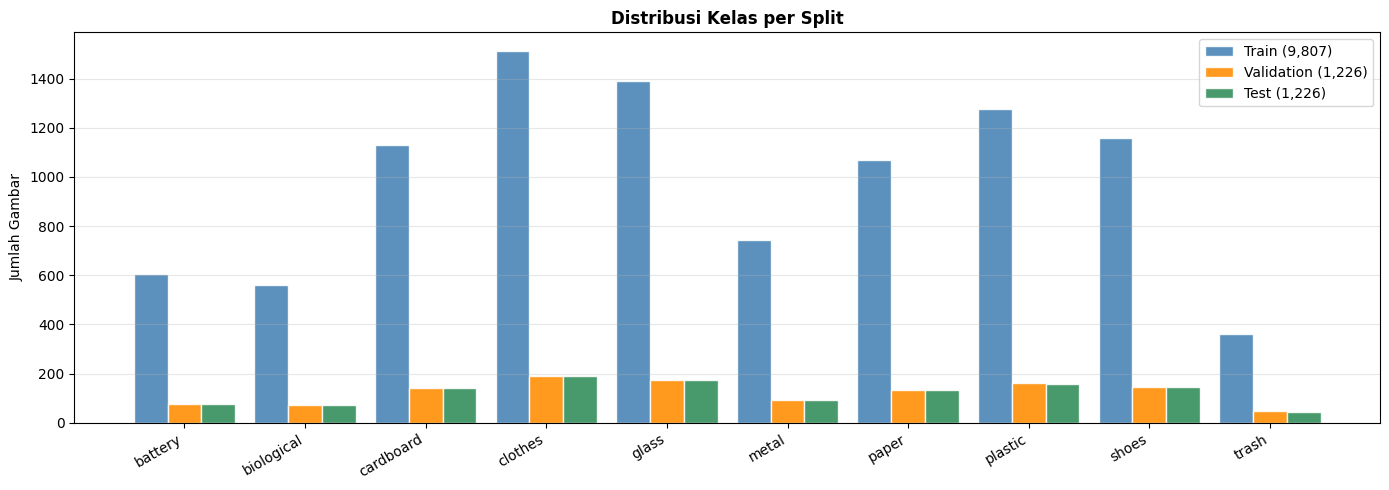

In [9]:
# Visualisasi distribusi kelas per split (Grouped Bar)
split_data = {
    'Train'     : Counter(y_train),
    'Validation': Counter(y_val),
    'Test'      : Counter(y_test)
}

x      = np.arange(NUM_CLASSES)
width  = 0.28
colors_split = ['steelblue', 'darkorange', 'seagreen']

fig, ax = plt.subplots(figsize=(14, 5))

for i, (split_name, cnt_map) in enumerate(split_data.items()):
    vals = [cnt_map[c] for c in CLASS_NAMES]
    offset = (i - 1) * width
    bars = ax.bar(x + offset, vals, width,
                  label=f"{split_name} ({sum(vals):,})",
                  color=colors_split[i], edgecolor='white', alpha=0.88)

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_title('Distribusi Kelas per Split',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Jumlah Gambar')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# FUNGSI-FUNGSI AUGMENTASI (cv2 + skimage)

def anticlockwise_rotation(img):
    """Rotasi berlawanan arah jarum jam dengan sudut acak."""
    img   = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img   = cv2.resize(img, (224, 224))
    sudut = random.randint(0, 30)
    return rotate(img, sudut)

def clockwise_rotation(img):
    """Rotasi searah jarum jam dengan sudut acak."""
    img   = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img   = cv2.resize(img, (224, 224))
    sudut = random.randint(0, 30)
    return rotate(img, -sudut)

def flip_left_right(img):
    """Balik gambar secara horizontal (kiri ke kanan)."""
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    return np.fliplr(img)

def add_brightness(img):
    """Tingkatkan kecerahan gambar dengan gamma correction."""
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    gamma = random.uniform(0.7, 1.3)
    return adjust_gamma(img, gamma=gamma, gain=1)

def blur_image(img):
    """Terapkan efek blur Gaussian pada gambar."""
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    return cv2.GaussianBlur(img, (3, 3), 0)

def sheared(img):
    """Terapkan efek shear (pergeseran diagonal) pada gambar."""
    img       = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img       = cv2.resize(img, (224, 224))
    transform = AffineTransform(shear=0.2)
    return warp(img, transform, mode='wrap')

def warp_shift(img):
    """Terapkan efek translasi/pergeseran pada gambar."""
    img       = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img       = cv2.resize(img, (224, 224))
    transform = AffineTransform(translation=(0, 40))
    return warp(img, transform, mode='wrap')

def add_noise(img):
    """Tambahkan noise acak pada gambar."""
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    img = img.astype(np.float64) / 255.0
    return random_noise(img, mode='gaussian', var=0.01)

# HAPUS flip_up_down — tidak cocok untuk dataset sampah
# GANTI dengan flip_left_right saja yang lebih natural

transformations = {
    'rotate_anticlockwise': anticlockwise_rotation,  # max 30°
    'rotate_clockwise'    : clockwise_rotation,       # max 30°
    'flip_left_right'     : flip_left_right,          # ← tetap
    'add_brightness'      : add_brightness,           # gamma 0.7-1.3
    'blur_image'          : blur_image,               # kernel (3,3)
    'shear_image'         : sheared,                  # tetap
    'warp_shift'          : warp_shift,               # tetap
    'add_noise'           : add_noise,                # tetap
}

print(f"✅ {len(transformations)} fungsi augmentasi siap:")
for name in transformations:
    print(f"   - {name}")

✅ 8 fungsi augmentasi siap:
   - rotate_anticlockwise
   - rotate_clockwise
   - flip_left_right
   - add_brightness
   - blur_image
   - shear_image
   - warp_shift
   - add_noise


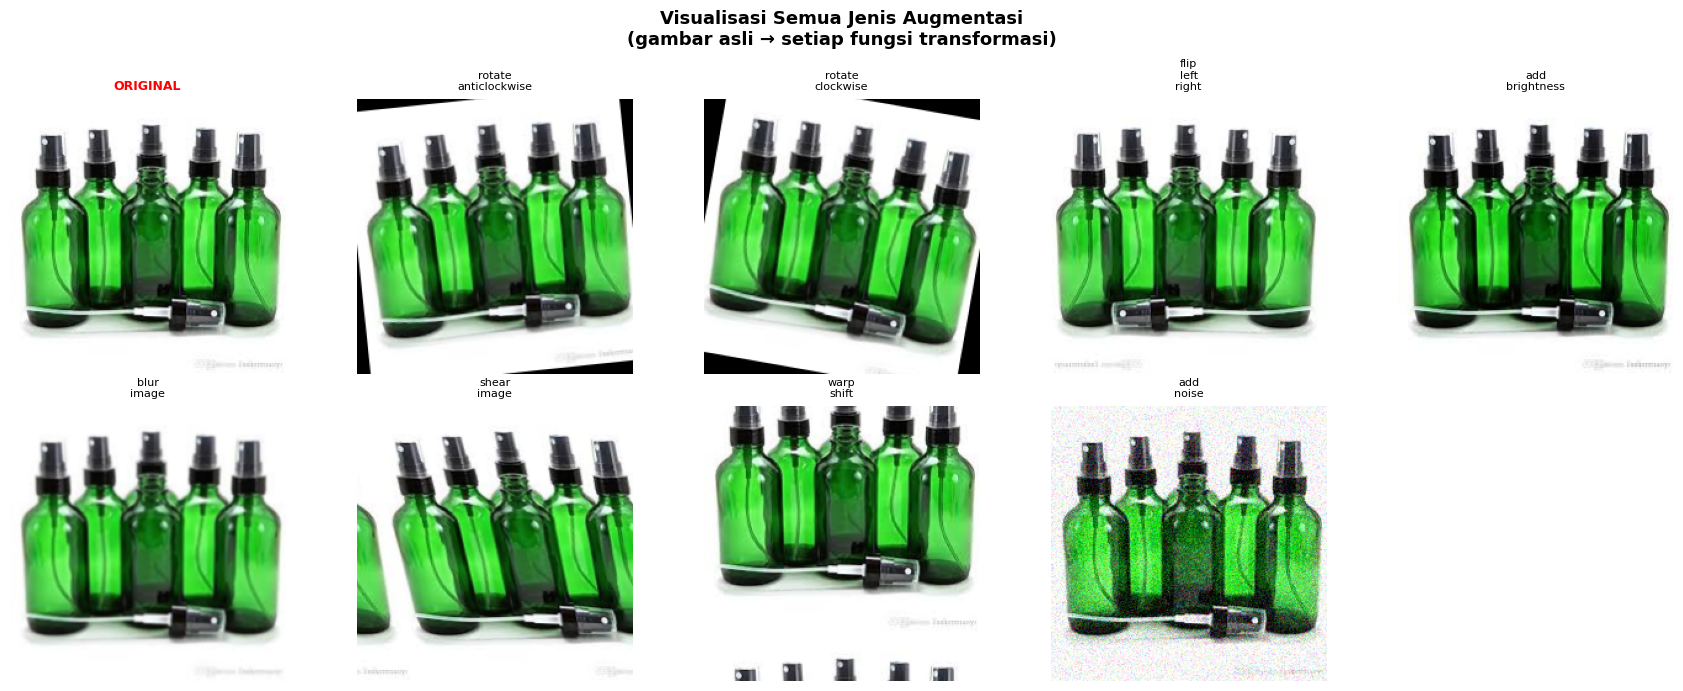

In [11]:
# Visualisasi semua jenis augmentasi pada 1 gambar
# Ambil 1 gambar sampel dari dataset
sample_path = random.choice(file_paths)
sample_img  = cv2.imread(sample_path)   # baca dengan cv2 (BGR)

n_transforms = len(transformations)
cols = 5
rows = (n_transforms + 1 + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.5))
axes = axes.flatten()
fig.suptitle(
    'Visualisasi Semua Jenis Augmentasi\n'
    '(gambar asli → setiap fungsi transformasi)',
    fontsize=13, fontweight='bold'
)

# Gambar original
orig_rgb = cv2.cvtColor(cv2.resize(sample_img, (224, 224)), cv2.COLOR_BGR2RGB)
axes[0].imshow(orig_rgb)
axes[0].set_title('ORIGINAL', fontsize=9, fontweight='bold', color='red')
axes[0].axis('off')

# Setiap transformasi
for i, (name, func) in enumerate(transformations.items(), start=1):
    try:
        aug = func(sample_img)
        aug = img_as_ubyte(aug) if aug.max() <= 1.0 else aug.astype(np.uint8)
        axes[i].imshow(aug)
    except Exception as e:
        axes[i].text(0.5, 0.5, f'Error:\n{e}', ha='center', va='center',
                     transform=axes[i].transAxes, fontsize=7, color='red')
    axes[i].set_title(name.replace('_', '\n'), fontsize=8)
    axes[i].axis('off')

# Sembunyikan axes kosong
for j in range(n_transforms + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [12]:
# AUGMENTASI HANYA pada X_train
AUG_TRAIN_DIR = Path("augmented/train")
TARGET_N      = max(Counter(y_train).values())  # target dari train saja

for cls in CLASS_NAMES:
    (AUG_TRAIN_DIR / cls).mkdir(parents=True, exist_ok=True)

for cls in CLASS_NAMES:
    cls_imgs  = [p for p, l in zip(X_train, y_train) if l == cls]
    current_n = len(cls_imgs)
    need_n    = TARGET_N - current_n

    if need_n <= 0:
        continue

    i = 1
    while i <= need_n:
        img_path = random.choice(cls_imgs)
        try:
            original_image = io.imread(img_path)
            n_transform    = random.randint(1, 3)
            transformed    = original_image.copy()

            for _ in range(n_transform):
                key         = random.choice(list(transformations))
                transformed = transformations[key](transformed)

            save_path   = AUG_TRAIN_DIR / cls / f"aug_{cls}_{i:05d}.jpg"
            transformed = img_as_ubyte(transformed) if transformed.max() <= 1.0 \
                          else transformed.astype(np.uint8)
            cv2.imwrite(str(save_path),
                        cv2.cvtColor(transformed, cv2.COLOR_RGB2BGR))
            i += 1
        except Exception:
            pass


In [13]:
# Gabungkan Train original + augmented
X_train_final, y_train_final = X_train.copy(), y_train.copy()

for cls in CLASS_NAMES:
    for p in (AUG_TRAIN_DIR / cls).iterdir():
        if p.suffix.lower() in VALID_EXT:
            X_train_final.append(str(p))
            y_train_final.append(cls)

# Val dan Test tetap HANYA gambar original — tidak berubah
print(f"Train  : {len(X_train_final):,} (original + augmented)")
print(f"Val    : {len(X_val):,}         (original only)")
print(f"Test   : {len(X_test):,}        (original only)")

Train  : 15,130 (original + augmented)
Val    : 1,226         (original only)
Test   : 1,226        (original only)


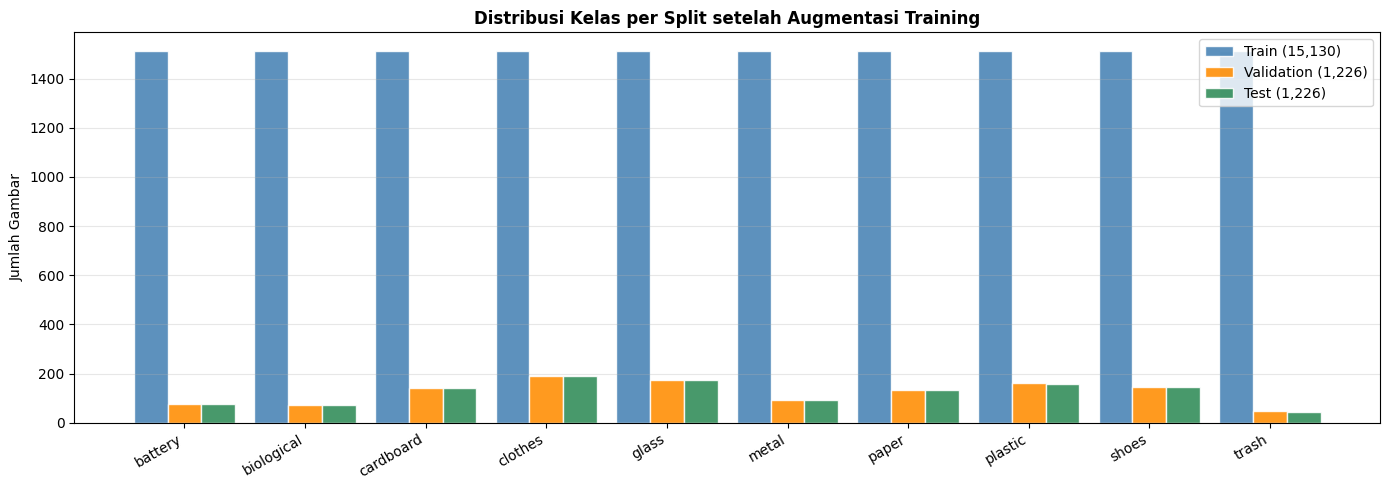

In [14]:
# Visualisasi distribusi kelas per split (Grouped Bar)
split_data = {
    'Train'     : Counter(y_train_final),
    'Validation': Counter(y_val),
    'Test'      : Counter(y_test)
}

x      = np.arange(NUM_CLASSES)
width  = 0.28
colors_split = ['steelblue', 'darkorange', 'seagreen']

fig, ax = plt.subplots(figsize=(14, 5))

for i, (split_name, cnt_map) in enumerate(split_data.items()):
    vals = [cnt_map[c] for c in CLASS_NAMES]
    offset = (i - 1) * width
    bars = ax.bar(x + offset, vals, width,
                  label=f"{split_name} ({sum(vals):,})",
                  color=colors_split[i], edgecolor='white', alpha=0.88)

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_title('Distribusi Kelas per Split setelah Augmentasi Training',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Jumlah Gambar')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

df_train = pd.DataFrame({'filename': X_train_final, 'class': y_train_final})
df_val   = pd.DataFrame({'filename': X_val,   'class': y_val})
df_test  = pd.DataFrame({'filename': X_test,  'class': y_test})

# Train — tambah augmentasi ringan
train_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    horizontal_flip        = True,
    rotation_range         = 15,
    zoom_range             = 0.10,
    brightness_range       = [0.8, 1.2],
    fill_mode              = 'nearest'
)

# Val & Test — rescale saja
val_test_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=df_train, x_col='filename', y_col='class',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True, seed=42
)
val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=df_val, x_col='filename', y_col='class',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)
test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=df_test, x_col='filename', y_col='class',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

CLASS_NAMES_ORDERED = list(train_generator.class_indices.keys())
print(f"Class indices : {train_generator.class_indices}")

Found 15130 validated image filenames belonging to 10 classes.
Found 1226 validated image filenames belonging to 10 classes.
Found 1226 validated image filenames belonging to 10 classes.
Class indices : {'battery': 0, 'biological': 1, 'cardboard': 2, 'clothes': 3, 'glass': 4, 'metal': 5, 'paper': 6, 'plastic': 7, 'shoes': 8, 'trash': 9}


In [16]:
# Hitung weight dari y_train ASLI (sebelum augmentasi)
# Mencerminkan kesulitan nyata tiap kelas di data asli
class_weights_arr = compute_class_weight(
    class_weight = 'balanced',
    classes      = np.array(CLASS_NAMES_ORDERED),  # ← dari generator
    y            = y_train                          # ← data ASLI, bukan y_train_final
)

# Konversi ke dict {index: weight}
class_weight_dict = dict(enumerate(class_weights_arr))

# Print ringkasan
print(f"\n{'Kelas':<18} {'Jumlah Asli':>12} {'Weight':>8}")
print("─" * 42)
count_train = Counter(y_train)
for i, cls in enumerate(CLASS_NAMES_ORDERED):
    w   = class_weight_dict[i]
    cnt = count_train[cls]
    bar = '█' * int(w * 5)
    print(f"  {cls:<16} {cnt:>12,} {w:>8.4f}  {bar}")


Kelas               Jumlah Asli   Weight
──────────────────────────────────────────
  battery                   605   1.6210  ████████
  biological                559   1.7544  ████████
  cardboard               1,129   0.8686  ████
  clothes                 1,513   0.6482  ███
  glass                   1,389   0.7060  ███
  metal                     744   1.3181  ██████
  paper                   1,069   0.9174  ████
  plastic                 1,278   0.7674  ███
  shoes                   1,159   0.8462  ████
  trash                     362   2.7091  █████████████


## Modelling

In [17]:
# Base model pretrained 
base_model = EfficientNetB1(
    weights     = 'imagenet',
    include_top = False,
    input_shape = (224, 224, 3)
)
base_model.trainable = False   # ← Freeze untuk Stage 1

# Model Sequential 
model = Sequential(name="GarbageCNN_EfficientNetB1")

# Input
model.add(InputLayer(shape=(224, 224, 3)))

# Base model (feature extractor pretrained)
model.add(base_model)

# Conv Block setelah base model 
# Output base_model: (7, 7, 1280) → Conv2D memperhalus fitur
model.add(Conv2D(256, (3, 3), padding='same', name='conv_top_1'))
model.add(BatchNormalization(name='bn_top_1'))
model.add(layers.Activation('relu', name='act_top_1'))
model.add(MaxPooling2D(pool_size=(2, 2), name='pool_top_1'))   

model.add(Conv2D(128, (3, 3), padding='same', name='conv_top_2'))
model.add(BatchNormalization(name='bn_top_2'))
model.add(layers.Activation('relu', name='act_top_2'))
model.add(MaxPooling2D(pool_size=(2, 2), name='pool_top_2'))   

# Feature Compression 
model.add(GlobalAveragePooling2D(name='global_avg_pool'))

# Classifier Head
model.add(BatchNormalization(name='bn_classifier'))
model.add(Dense(256, activation='relu',
                kernel_regularizer=regularizers.l2(1e-4), name='fc1'))
model.add(Dropout(0.50, name='dropout1'))
model.add(Dense(NUM_CLASSES, activation='softmax', name='output'))

# Compile Stage 1 
model.compile(
    optimizer = Adam(learning_rate=1e-3),
    loss      = tf.keras.losses.CategoricalCrossentropy(
                    label_smoothing=0.05   # ← label smoothing seperti referensi
                ),
    metrics   = ['accuracy']
)

model.summary(line_length=75)

I0000 00:00:1775491532.504667      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1775491532.510440      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


27018416/27018416 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "GarbageCNN_EfficientNetB1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                   ┃ Output Shape            ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ efficientnetb1 (Functional)    │ (None, 7, 7, 1280)      │    6,575,239 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ conv_top_1 (Conv2D)            │ (None, 7, 7, 256)       │    2,949,376 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ bn_top_1 (BatchNormalization)  │ (None, 7, 7, 256)       │        1,024 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ act_top_1 (Activation)         │ (None, 7, 7, 256)       │            0 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ pool_top_1 (MaxPooling2D)      │ (None, 3, 3, 256)       │            0 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ conv_top_2 (Conv2D)            │ (None, 3, 3, 128)       │      295,040 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ bn_top_2 (BatchNormalization)  │ (None, 3, 3, 128)       │          512 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ act_top_2 (Activation)         │ (None, 3, 3, 128)       │            0 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ pool_top_2 (MaxPooling2D)      │ (None, 1, 1, 128)       │            0 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ global_avg_pool                │ (None, 128)             │            0 │
│ (GlobalAveragePooling2D)       │                         │              │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ bn_classifier                  │ (None, 128)             │          512 │
│ (BatchNormalization)           │                         │              │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ fc1 (Dense)                    │ (None, 256)             │       33,024 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ dropout1 (Dropout)             │ (None, 256)             │            0 │
├────────────────────────────────┼─────────────────────────┼──────────────┤
│ output (Dense)                 │ (None, 10)              │        2,570 │
└────────────────────────────────┴─────────────────────────┴──────────────┘

 Total params: 9,857,297 (37.60 MB)

 Trainable params: 3,281,034 (12.52 MB)

 Non-trainable params: 6,576,263 (25.09 MB)

In [18]:
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("logs",        exist_ok=True)

def make_callbacks(log_file):
    return [
        ModelCheckpoint(
            'checkpoints/best_model.keras',
            monitor='val_accuracy', save_best_only=True,
            mode='max', verbose=1
        ),
        EarlyStopping(
            monitor='val_accuracy', patience=5,
            restore_best_weights=True, mode='max', verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=3, min_lr=1e-7, verbose=1
        ),
        CSVLogger(f'logs/{log_file}', append=False)
    ]



In [19]:
# STAGE 1 — Latih Conv + Classifier Head saja, Base model EfficientNetB1 di-FREEZE

base_model.trainable = False
history_stage1 = model.fit(
    train_generator,
    epochs          = 15,
    validation_data = val_generator,
    callbacks       = make_callbacks('training_log_stage1.csv'),
    class_weight    = class_weight_dict,
    verbose         = 1
)

best_s1 = max(history_stage1.history['val_accuracy']) * 100
print(f"\n✅ Stage 1 selesai — Best val_accuracy: {best_s1:.2f}%")

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15


I0000 00:00:1775491553.455549     138 service.cc:152] XLA service 0x7d8afd29bfe0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1775491553.455584     138 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1775491553.455587     138 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1775491556.746365     138 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-06 16:06:05.859374: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:06:06.002008: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:06:06.339610: E external/local_xl

348/473 ━━━━━━━━━━━━━━━━━━━━ 58s 468ms/step - accuracy: 0.7159 - loss: 1.2789

2026-04-06 16:09:13.062038: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:09:13.204333: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:09:13.534815: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:09:13.675691: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:09:14.457242: E external/local_xla/xla/stream_

473/473 ━━━━━━━━━━━━━━━━━━━━ 0s 521ms/step - accuracy: 0.7432 - loss: 1.1923

2026-04-06 16:10:52.052098: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:10:52.188933: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:10:52.497247: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:10:52.637923: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:10:53.414749: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from -inf to 0.91272, saving model to checkpoints/best_model.keras
473/473 ━━━━━━━━━━━━━━━━━━━━ 323s 595ms/step - accuracy: 0.7433 - loss: 1.1918 - val_accuracy: 0.9127 - val_loss: 0.5828 - learning_rate: 0.0010
Epoch 2/15
473/473 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - accuracy: 0.9060 - loss: 0.6675
Epoch 2: val_accuracy improved from 0.91272 to 0.92577, saving model to checkpoints/best_model.keras
473/473 ━━━━━━━━━━━━━━━━━━━━ 200s 422ms/step - accuracy: 0.9060 - loss: 0.6675 - val_accuracy: 0.9258 - val_loss: 0.5267 - learning_rate: 0.0010
Epoch 3/15
473/473 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step - accuracy: 0.9340 - loss: 0.5938
Epoch 3: val_accuracy improved from 0.92577 to 0.93067, saving model to checkpoints/best_model.keras
473/473 ━━━━━━━━━━━━━━━━━━━━ 199s 420ms/step - accuracy: 0.9341 - loss: 0.5938 - val_accuracy: 0.9307 - val_loss: 0.5214 - learning_rate: 0.0010
Epoch 4/15
473/473 ━━━━━━━━━━━━━━━━━━━━ 0s 416ms/step - accuracy: 0.9510 - loss: 0.5348


In [20]:
# STAGE 2 — Fine-tune SELURUH model, Unfreeze EfficientNetB1 dengan LR lebih kecil

# Unfreeze semua layer
base_model.trainable = True

# Compile ulang dengan LR lebih kecil
model.compile(
    optimizer = Adam(learning_rate=1e-4),
    loss      = tf.keras.losses.CategoricalCrossentropy(
                    label_smoothing=0.05
                ),
    metrics   = ['accuracy']
)

history_stage2 = model.fit(
    train_generator,
    epochs          = 10,
    validation_data = val_generator,
    callbacks       = make_callbacks('training_log_stage2.csv'),
    class_weight    = class_weight_dict,
    verbose         = 1
)

best_s2 = max(history_stage2.history['val_accuracy']) * 100
print(f"\n✅ Stage 2 selesai — Best val_accuracy: {best_s2:.2f}%")

Epoch 1/10


2026-04-06 16:58:44.670603: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 16:58:44.822195: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


221/473 ━━━━━━━━━━━━━━━━━━━━ 1:50 440ms/step - accuracy: 0.8780 - loss: 0.7210

2026-04-06 17:01:16.632597: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 17:01:16.779951: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 17:01:21.686314: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-06 17:01:21.828308: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


473/473 ━━━━━━━━━━━━━━━━━━━━ 0s 552ms/step - accuracy: 0.8990 - loss: 0.6617
Epoch 1: val_accuracy improved from -inf to 0.93964, saving model to checkpoints/best_model.keras
473/473 ━━━━━━━━━━━━━━━━━━━━ 386s 597ms/step - accuracy: 0.8991 - loss: 0.6615 - val_accuracy: 0.9396 - val_loss: 0.4667 - learning_rate: 1.0000e-04
Epoch 2/10
473/473 ━━━━━━━━━━━━━━━━━━━━ 0s 426ms/step - accuracy: 0.9636 - loss: 0.4754
Epoch 2: val_accuracy improved from 0.93964 to 0.94372, saving model to checkpoints/best_model.keras
473/473 ━━━━━━━━━━━━━━━━━━━━ 207s 438ms/step - accuracy: 0.9636 - loss: 0.4753 - val_accuracy: 0.9437 - val_loss: 0.4483 - learning_rate: 1.0000e-04
Epoch 3/10
473/473 ━━━━━━━━━━━━━━━━━━━━ 0s 432ms/step - accuracy: 0.9825 - loss: 0.4284
Epoch 3: val_accuracy improved from 0.94372 to 0.95351, saving model to checkpoints/best_model.keras
473/473 ━━━━━━━━━━━━━━━━━━━━ 210s 444ms/step - accuracy: 0.9825 - loss: 0.4284 - val_accuracy: 0.9535 - val_loss: 0.4363 - learning_rate: 1.0000e-04


## Evaluasi dan Visualisasi

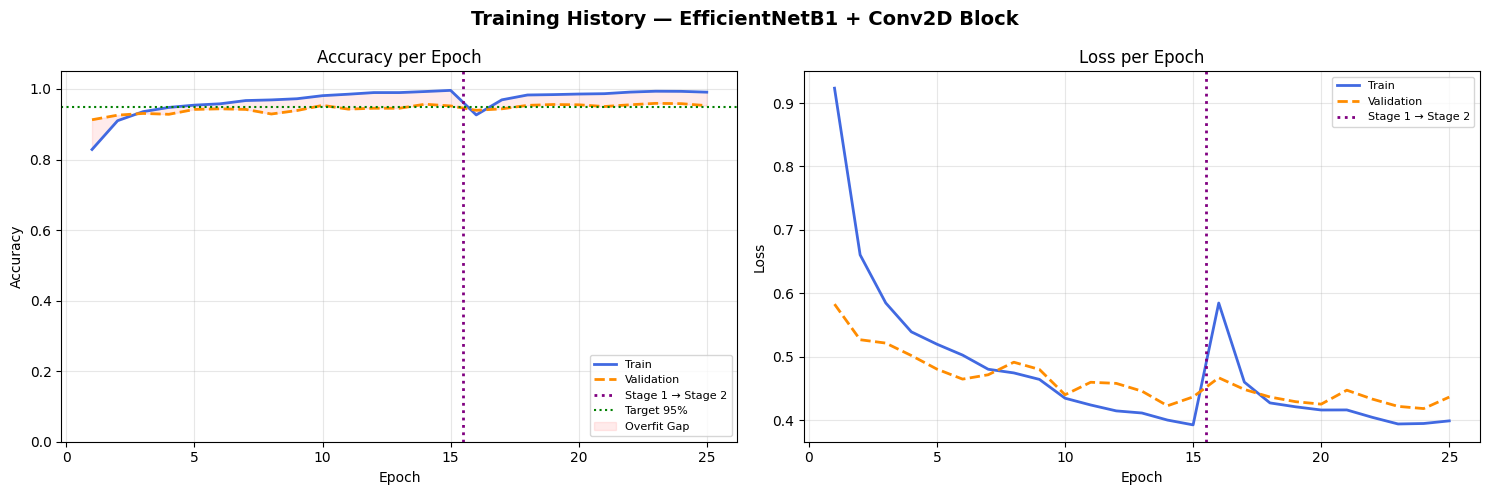

In [21]:
# PLOT — Gabungkan history Stage 1 + Stage 2

def merge_history(h1, h2, keys):
    merged = {}
    for k in keys:
        merged[k] = h1.history[k] + h2.history[k]
    return merged

hist = merge_history(
    history_stage1, history_stage2,
    ['accuracy', 'val_accuracy', 'loss', 'val_loss']
)

epochs_ran    = range(1, len(hist['accuracy']) + 1)
stage_switch  = len(history_stage1.history['accuracy'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Training History — EfficientNetB1 + Conv2D Block',
             fontsize=14, fontweight='bold')

# Accuracy
ax = axes[0]
ax.plot(epochs_ran, hist['accuracy'],     lw=2, color='royalblue',  label='Train')
ax.plot(epochs_ran, hist['val_accuracy'], lw=2, color='darkorange', label='Validation', ls='--')
ax.axvline(stage_switch + 0.5, color='purple', ls=':', lw=2, label='Stage 1 → Stage 2')
ax.axhline(0.95, color='green', lw=1.5, ls=':', label='Target 95%')
ax.fill_between(epochs_ran, hist['accuracy'], hist['val_accuracy'],
                alpha=0.08, color='red', label='Overfit Gap')
ax.set_title('Accuracy per Epoch')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.set_ylim([0, 1.05])
ax.legend(loc='lower right', fontsize=8)
ax.grid(True, alpha=0.3)

# Loss
ax = axes[1]
ax.plot(epochs_ran, hist['loss'],     lw=2, color='royalblue',  label='Train')
ax.plot(epochs_ran, hist['val_loss'], lw=2, color='darkorange', label='Validation', ls='--')
ax.axvline(stage_switch + 0.5, color='purple', ls=':', lw=2, label='Stage 1 → Stage 2')
ax.set_title('Loss per Epoch')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# Evaluasi pada Train / Val / Test 
# Gunakan val_test_datagen (TANPA augmentasi) untuk evaluasi train
# agar hasil konsisten dan tidak terpengaruh augmentasi
train_eval_gen = val_test_datagen.flow_from_dataframe(
    dataframe   = df_train,
    x_col       = 'filename',
    y_col       = 'class',
    target_size = IMG_SIZE,
    batch_size  = BATCH_SIZE,
    class_mode  = 'categorical',
    shuffle     = False
)

train_loss, train_acc = model.evaluate(train_eval_gen, verbose=0)
val_loss,   val_acc   = model.evaluate(val_generator,  verbose=0)
test_loss,  test_acc  = model.evaluate(test_generator, verbose=0)

print("═" * 46)
print(f"  {'Set':<14} {'Loss':>8} {'Accuracy':>12}")
print("─" * 46)
print(f"  {'Train':<14} {train_loss:>8.4f} {train_acc*100:>11.2f}%")
print(f"  {'Validation':<14} {val_loss:>8.4f} {val_acc*100:>11.2f}%")
print(f"  {'Test':<14} {test_loss:>8.4f} {test_acc*100:>11.2f}%")
print("═" * 46)
for label, acc in [("Train", train_acc), ("Test", test_acc)]:
    icon = "✅ LULUS" if acc >= 0.95 else "⚠️  BELUM"
    print(f"  {label} ≥ 95%: {icon} ({acc*100:.2f}%)")

Found 15130 validated image filenames belonging to 10 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


══════════════════════════════════════════════
  Set                Loss     Accuracy
──────────────────────────────────────────────
  Train            0.2990       99.99%
  Validation       0.4216       95.92%
  Test             0.4242       95.68%
══════════════════════════════════════════════
  Train ≥ 95%: ✅ LULUS (99.99%)
  Test ≥ 95%: ✅ LULUS (95.68%)


39/39 ━━━━━━━━━━━━━━━━━━━━ 21s 317ms/step


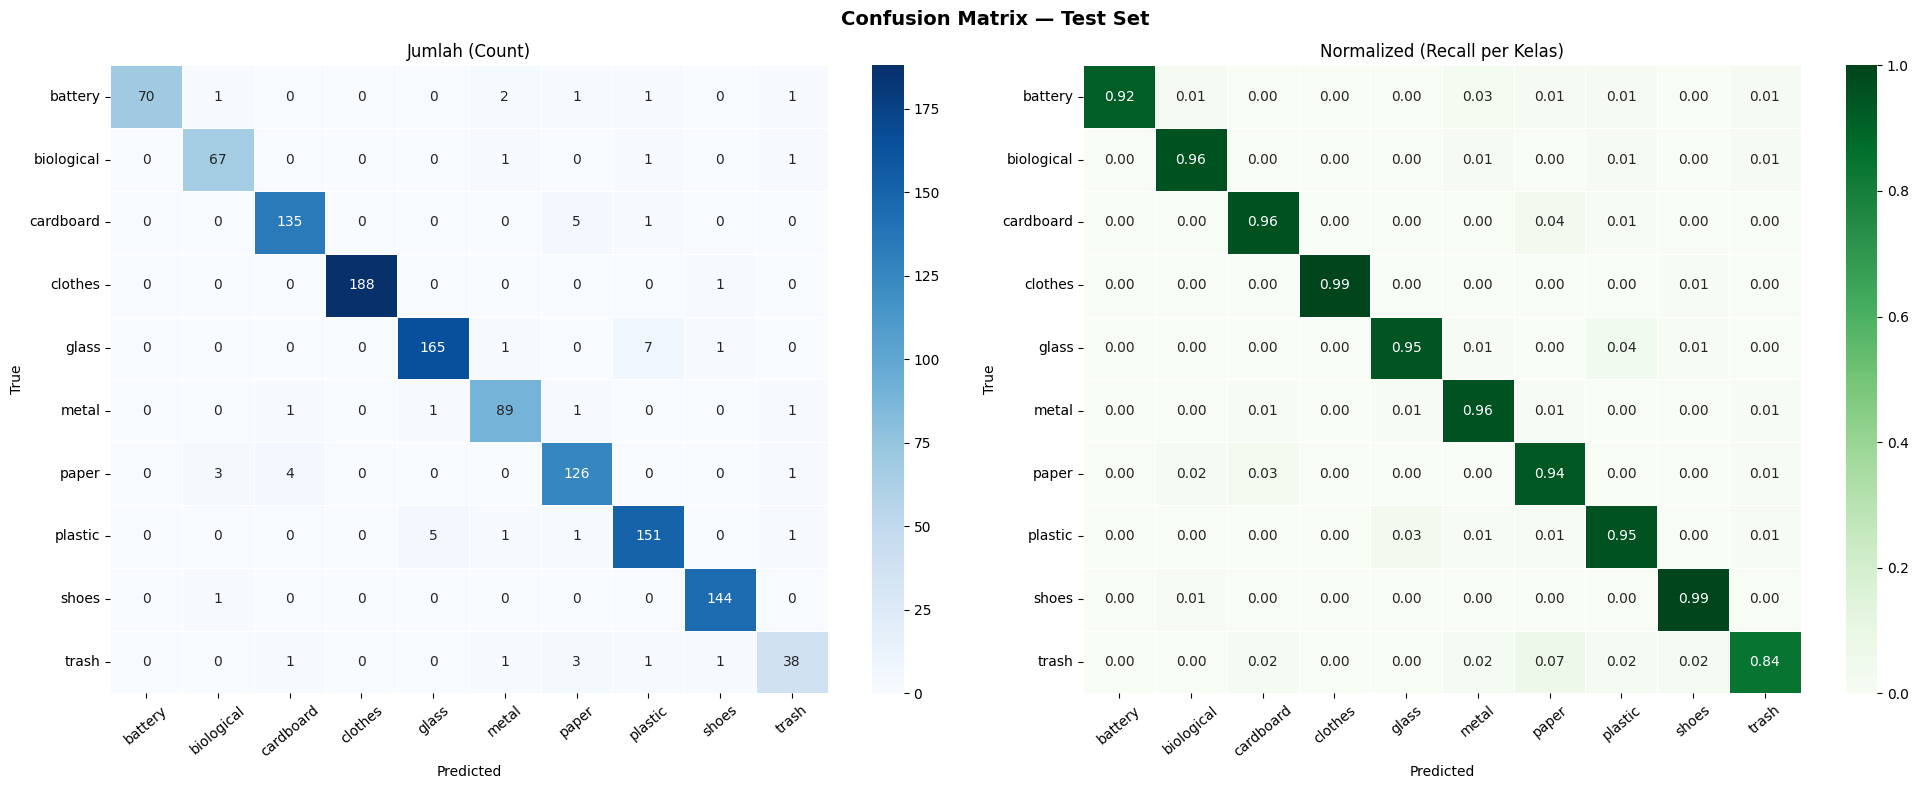


📋 Classification Report:
              precision    recall  f1-score   support

     battery       1.00      0.92      0.96        76
  biological       0.93      0.96      0.94        70
   cardboard       0.96      0.96      0.96       141
     clothes       1.00      0.99      1.00       189
       glass       0.96      0.95      0.96       174
       metal       0.94      0.96      0.95        93
       paper       0.92      0.94      0.93       134
     plastic       0.93      0.95      0.94       159
       shoes       0.98      0.99      0.99       145
       trash       0.88      0.84      0.86        45

    accuracy                           0.96      1226
   macro avg       0.95      0.95      0.95      1226
weighted avg       0.96      0.96      0.96      1226



In [23]:
# Confusion Matrix 
test_generator.reset()
y_pred_proba = model.predict(test_generator, verbose=1)
y_pred       = np.argmax(y_pred_proba, axis=1)
y_true       = test_generator.classes

cm      = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)  # normalisasi

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle('Confusion Matrix — Test Set', fontsize=14, fontweight='bold')

# Raw count
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES_ORDERED,
            yticklabels=CLASS_NAMES_ORDERED,
            ax=axes[0], linewidths=0.5)
axes[0].set_title('Jumlah (Count)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')
axes[0].tick_params(axis='x', rotation=40)

# Normalized (persentase per baris)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=CLASS_NAMES_ORDERED,
            yticklabels=CLASS_NAMES_ORDERED,
            ax=axes[1], linewidths=0.5,
            vmin=0, vmax=1)
axes[1].set_title('Normalized (Recall per Kelas)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')
axes[1].tick_params(axis='x', rotation=40)

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES_ORDERED))

## Konversi Model

In [25]:
#Menyimpan Model
SAVED_MODEL_PATH = str(SAVED_MODEL_DIR)

model.export(SAVED_MODEL_PATH)

print(f"SavedModel disimpan di: {SAVED_MODEL_PATH}")

INFO:tensorflow:Assets written to: /kaggle/working/saved_model/assets


INFO:tensorflow:Assets written to: /kaggle/working/saved_model/assets


Saved artifact at '/kaggle/working/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_340')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  138036562018384: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  138036562020880: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  138037592418128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592414864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592416784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138039928061008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592419280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592419472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592421200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592421392: TensorSpec(shape=(), dtype=tf.res

In [26]:
# Konversi ke tflite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

# Simpan model
with open(TFLITE_PATH, "wb") as f:
    f.write(tflite_model)

print(f"TFLite disimpan di: {TFLITE_PATH}")

# Simpan label
with open(LABEL_PATH, "w") as f:
    for cls in CLASS_NAMES_ORDERED:
        f.write(cls + "\n")

print(f"Label disimpan di: {LABEL_PATH}")

INFO:tensorflow:Assets written to: /tmp/tmpgp9s4ty1/assets


INFO:tensorflow:Assets written to: /tmp/tmpgp9s4ty1/assets


Saved artifact at '/tmp/tmpgp9s4ty1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_340')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  138036562018384: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  138036562020880: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  138037592418128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592414864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592416784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138039928061008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592419280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592419472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592421200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138037592421392: TensorSpec(shape=(), dtype=tf.resource, name

W0000 00:00:1775497405.587666      55 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1775497405.587709      55 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1775497405.923672      55 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled


TFLite disimpan di: /kaggle/working/tflite/model.tflite
Label disimpan di: /kaggle/working/tflite/label.txt


In [27]:
# Konversi ke tfjs
!pip install tensorflowjs -q

import tensorflowjs as tfjs

TFJS_PATH = str(TFJS_DIR)

tfjs.converters.save_keras_model(model, TFJS_PATH)

print(f"TFJS model disimpan di: {TFJS_PATH}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.35.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-adk 1.25.1 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
ray 2.54.0 requires packaging>=24.2, but you have packaging 23.2 which is incompatible.
build 1.4.0 requires packaging>=24.0, but you have packaging 23.2 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
db-dtypes 1.5.0 requires pa

failed to lookup keras version from the file,
    this is likely a weight only file
weight normalization/count with shape () and dtype int64 was auto converted to the type int32
TFJS model disimpan di: /kaggle/working/tfjs_model


## Inference (Optional)

In [58]:
# INFERENCE — Menggunakan TF-Lite

# Load TF-Lite Interpreter 
interpreter = tf.lite.Interpreter(
    model_path = str(WORK_DIR / "tflite" / "model.tflite")
)
interpreter.allocate_tensors()

input_details  = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("✅ TF-Lite Interpreter berhasil di-load")
print(f"   Input  : shape={input_details[0]['shape']}  "
      f"dtype={input_details[0]['dtype']}")
print(f"   Output : shape={output_details[0]['shape']}")

✅ TF-Lite Interpreter berhasil di-load
   Input  : shape=[  1 224 224   3]  dtype=<class 'numpy.float32'>
   Output : shape=[ 1 10]


In [62]:
# Fungsi Inference 
def predict_tflite(img_path: str) -> dict:
    """
    Inferensi satu gambar menggunakan TF-Lite interpreter.

    Parameters
    ----------
    img_path : str
        Path ke file gambar

    Returns
    -------
    dict
        predicted_class, confidence, all_probs
    """
    # Load & preprocess — WAJIB pakai preprocess_input EfficientNet
    img = Image.open(img_path).convert('RGB').resize((224, 224))
    arr = preprocess_input(                      # ← bukan / 255.0 !
        np.array(img, dtype=np.float32)
    )
    arr = np.expand_dims(arr, axis=0)            # (1, 224, 224, 3)

    # Inference
    interpreter.set_tensor(input_details[0]['index'], arr)
    interpreter.invoke()
    probs = interpreter.get_tensor(
        output_details[0]['index']
    )[0]

    pred_idx = int(np.argmax(probs))

    return {
        'predicted_class': CLASS_NAMES_ORDERED[pred_idx],
        'confidence'     : float(probs[pred_idx]) * 100,
        'all_probs'      : {
            CLASS_NAMES_ORDERED[i]: round(float(probs[i]) * 100, 2)
            for i in range(len(CLASS_NAMES_ORDERED))
        }
    }

══════════════════════════════════════════════════════════════
  True Label         Predicted          Confidence
──────────────────────────────────────────────────────────────
  battery            battery                 95.0%  ✅
  biological         biological              96.5%  ✅
  cardboard          cardboard               90.9%  ✅
  clothes            clothes                 98.1%  ✅
  glass              glass                   57.9%  ✅
  metal              metal                   96.5%  ✅
  paper              paper                   96.5%  ✅
  plastic            plastic                 91.4%  ✅
  shoes              shoes                   96.9%  ✅
  trash              trash                   95.3%  ✅
══════════════════════════════════════════════════════════════
  Benar : 10/10 (100%)


/tmp/ipykernel_55/1421736635.py:52: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_55/1421736635.py:52: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


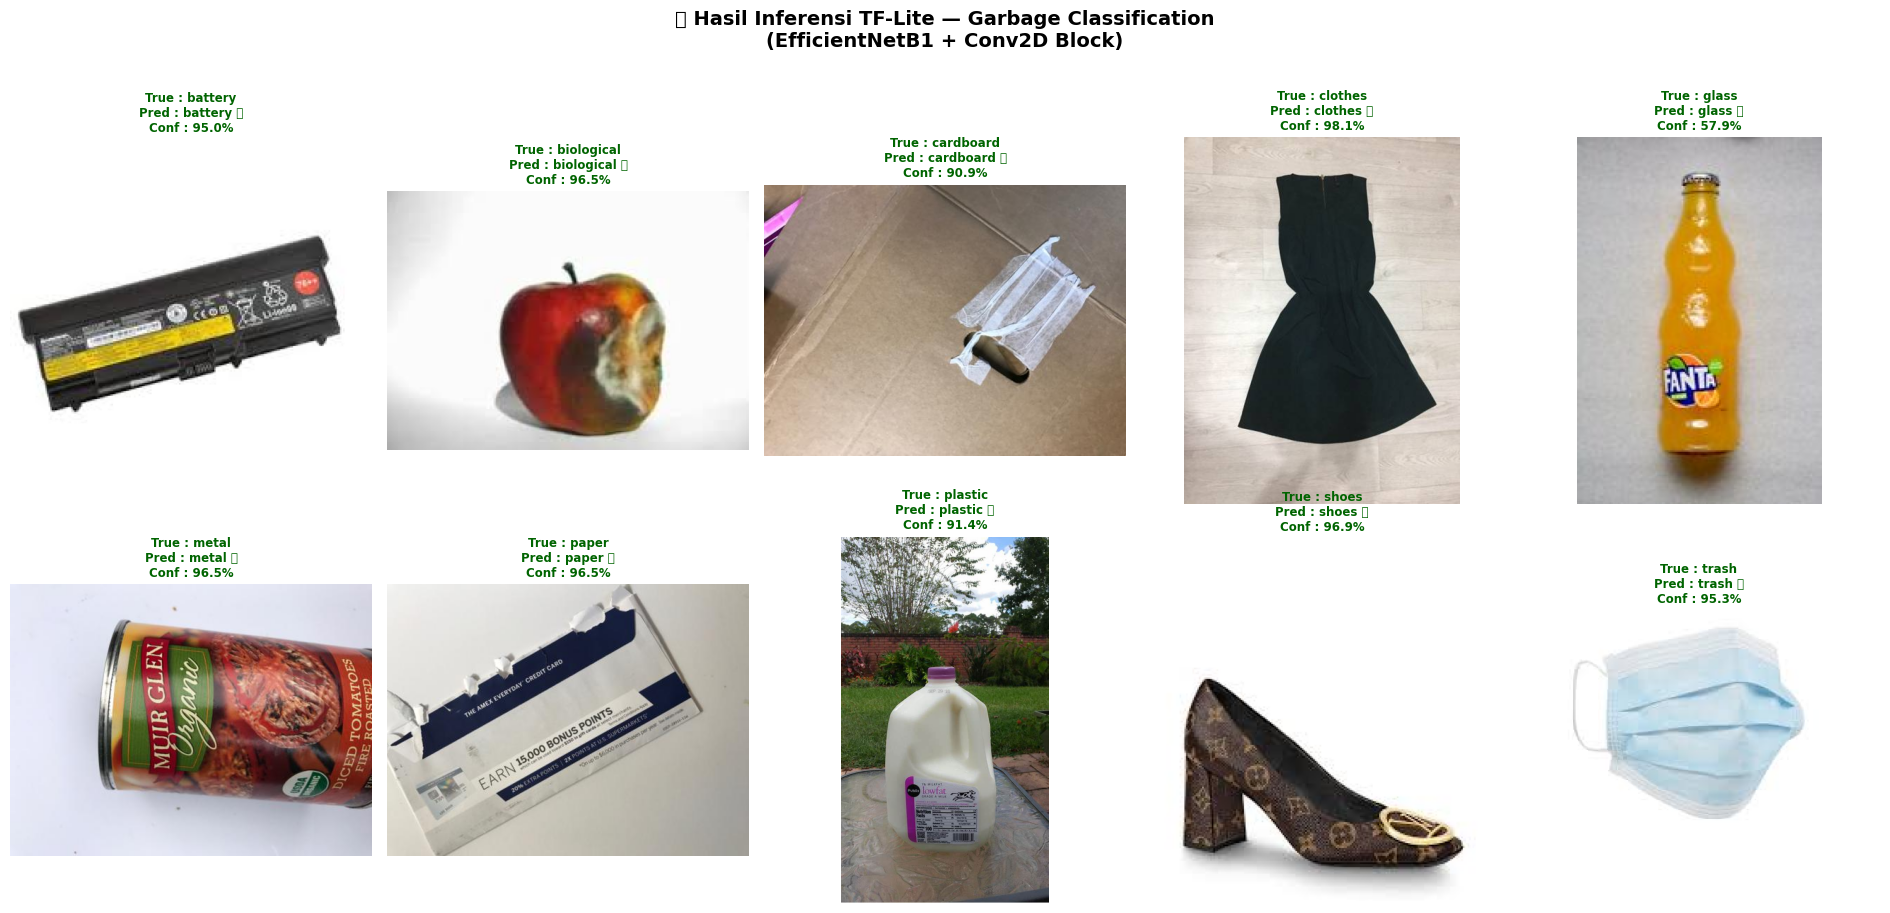

In [64]:
# Inferensi 1 gambar per kelas dari Test Set 
sample_images = [
    (cls, random.choice([p for p, l in zip(X_test, y_test) if l == cls]))
    for cls in CLASS_NAMES_ORDERED
]

# Visualisasi Grid 
cols = 5
rows = (len(sample_images) + cols - 1) // cols

fig, axes = plt.subplots(rows, cols,
                         figsize=(cols * 3.8, rows * 4.5))
axes = axes.flatten()
fig.suptitle(
    '🔍 Hasil Inferensi TF-Lite — Garbage Classification\n'
    '(EfficientNetB1 + Conv2D Block)',
    fontsize=14, fontweight='bold', y=1.01
)

print("═" * 62)
print(f"  {'True Label':<18} {'Predicted':<18} {'Confidence':>10}")
print("─" * 62)

correct = 0
for idx, (true_cls, img_path) in enumerate(sample_images):
    result   = predict_tflite(img_path)
    pred_cls = result['predicted_class']
    conf     = result['confidence']
    ok       = pred_cls == true_cls
    if ok:
        correct += 1
    icon  = "✅" if ok else "❌"
    color = 'darkgreen' if ok else 'crimson'

    axes[idx].imshow(mpimg.imread(img_path))
    axes[idx].set_title(
        f"True : {true_cls}\n"
        f"Pred : {pred_cls} {icon}\n"
        f"Conf : {conf:.1f}%",
        fontsize=8.5, color=color, fontweight='bold'
    )
    axes[idx].axis('off')
    print(f"  {true_cls:<18} {pred_cls:<18} {conf:>9.1f}%  {icon}")

print("═" * 62)
print(f"  Benar : {correct}/{len(sample_images)} "
      f"({correct/len(sample_images)*100:.0f}%)")

for j in range(len(sample_images), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()